Problem Statement- We want to predict flower type(species) based on features like -

Sepal length
Sepal width
Petal Length
petal width

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=sns.load_dataset("iris")

In [ ]:
#Logisctic Regression is not preferred as this is a more complex dataset and the  lr is
# primarily used for a binary classification model

In [3]:
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:
#here, the target column is an object -> we have to encode it later

In [5]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
df.isnull().sum()
#no nulls

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
#only 1 so we drop it
df.drop_duplicates(inplace=True)

In [10]:
df.shape

(149, 5)

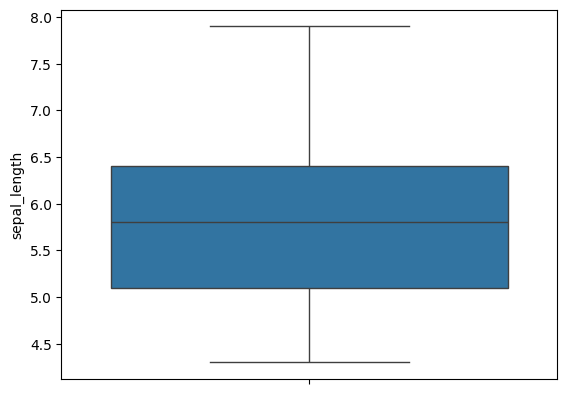

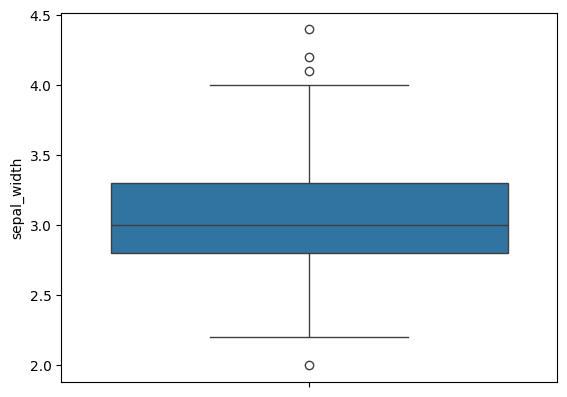

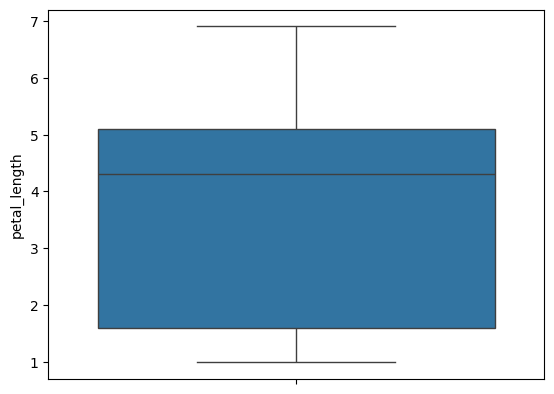

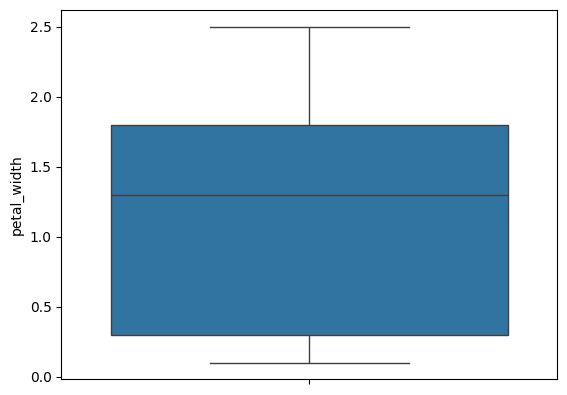

In [11]:
#now, checking for ouliers
for col in df.columns:
  if df[col].dtype!='object':
    sns.boxplot(df[col])
    plt.show()

In [ ]:
#not many outliers -> we can proceed with encoding

In [12]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [13]:
for col in df.columns:
  if df[col].dtype=='object':
    df[col]=le.fit_transform(df[col])

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 149 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  149 non-null    float64
 1   sepal_width   149 non-null    float64
 2   petal_length  149 non-null    float64
 3   petal_width   149 non-null    float64
 4   species       149 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 7.0 KB


In [21]:
df['species'].value_counts()

,count
species,
0,50
1,50
2,49


In [15]:
#now we start model buidling
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier

In [17]:
x=df.drop('species',axis=1)
y=df['species']

In [16]:
model=DecisionTreeClassifier()

In [28]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)

In [29]:
model.fit(x_train,y_train)

DecisionTreeClassifier()

In [30]:
y_pred=model.predict(x_test)
y_pred

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 1, 0, 0, 2, 1, 0])

In [31]:
accuracy_score(y_pred,y_test)*100

100.0

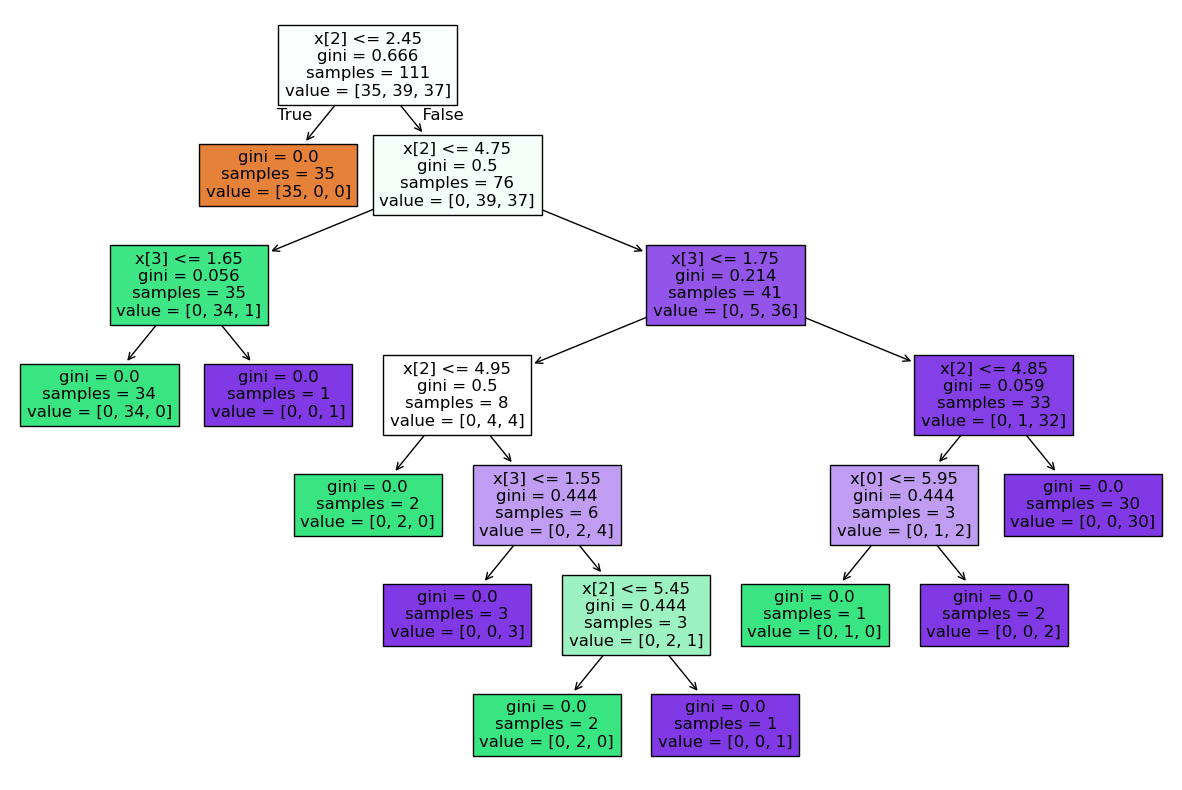

In [32]:
#we can show the decision tree figure too
from sklearn import tree
plt.figure(figsize=(15,10))
tree.plot_tree(model,filled=True) #we are specifying the annotations in it also
plt.show()


In [ ]:
# we can also omit the label encoding part, it will handle the categorical data values

In [33]:
# suppose, we want to give a hyperparameter max depth
model2=DecisionTreeClassifier(max_depth=3)

In [34]:
model2.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=3)

In [35]:
y_pred=model2.predict(x_test)

In [36]:
accuracy_score(y_pred,y_test)

1.0

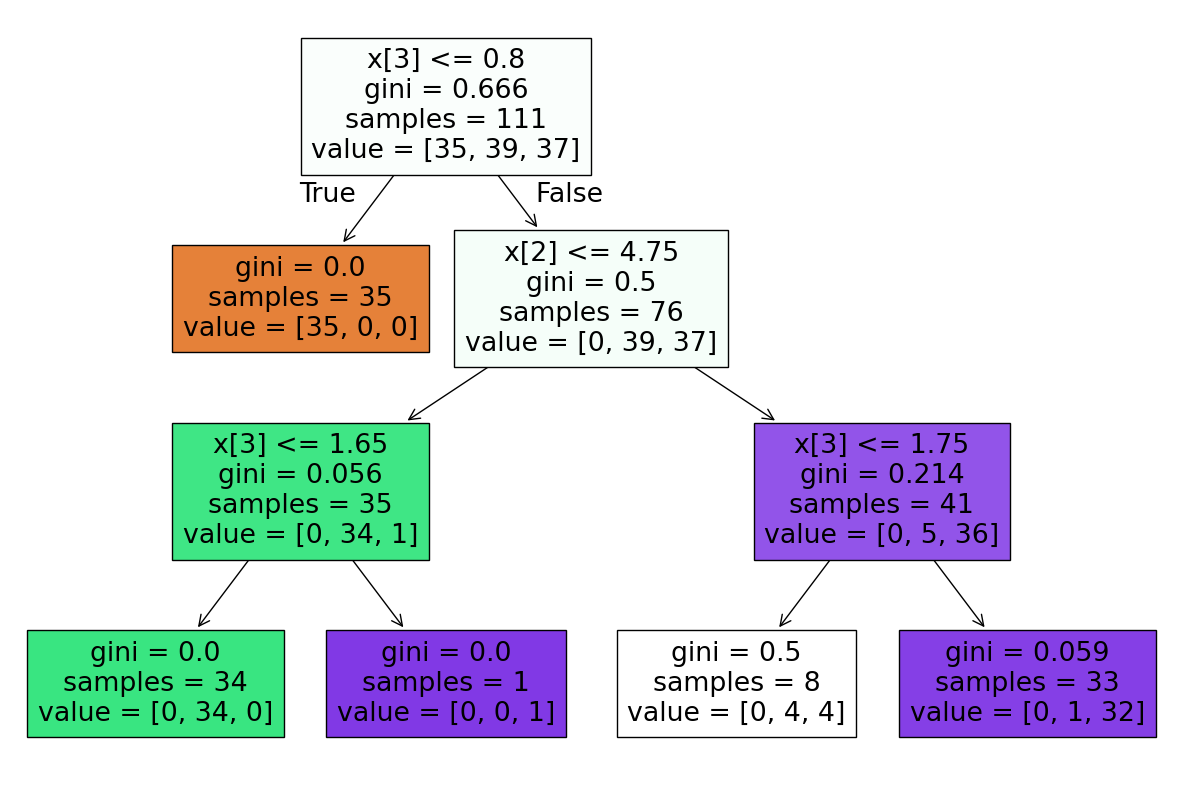

In [38]:
#plot for this too
from sklearn import tree
plt.figure(figsize=(15,10))
tree.plot_tree(model2,filled=True) #we are specifying the annotations in it also
plt.show()

A classification report is a text-based evaluation metric used to judge the performance of a machine learning classification model. It provides a breakdown of how well the model predicts each individual class, rather than giving just a single overall accuracy score

#The Four Core Metrics

A standard classification report (like the one generated by scikit-learn) displays a table with the following columns:

Precision: Out of all the examples the model predicted as positive, how many were actually positive? It measures the cost of false positives.

Recall (Sensitivity): Out of all the actual positive examples, how many did the model successfully find? It measures the cost of false negatives.

F1-Score: The harmonic mean of precision and recall. It gives you a single score that balances both metrics, which is highly useful for imbalanced datasets.

Support: The actual number of occurrences of each class in your specified dataset. It shows how balanced or imbalanced your test data is.

#Understanding the Averages

At the bottom of the report, you will find three types of summary rows:


Accuracy: The overall percentage of correctly predicted instances across the entire dataset.


Macro Average: The unweighted average of precision, recall, and F1-score across all classes. It treats all classes equally, regardless of how many samples they have.


Weighted Average: The average of precision, recall, and F1-score, but weighted by the support (number of instances) of each class. This is useful if you want a score that reflects the true distribution of your data.

In [41]:
from sklearn.metrics import classification_report

In [42]:
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       1.00      1.00      1.00        11
           2       1.00      1.00      1.00        12

    accuracy                           1.00        38
   macro avg       1.00      1.00      1.00        38
weighted avg       1.00      1.00      1.00        38

